# Project 3: Customer Churn Prediction

This notebook builds an end-to-end classification workflow that predicts whether a telecom customer is likely to cancel the service, and identifies the factors that drive churn.

**Workflow:** data loading, cleaning, exploratory analysis, preprocessing, feature engineering, model comparison, threshold selection, evaluation, driver analysis, model saving and prediction on new data.

## 1. Project Introduction

Winning a new customer usually costs far more than keeping an existing one, so telecom companies try to find customers who are about to leave and act before they do. The Telco Customer Churn dataset describes 7,043 customers of a telecom provider: their demographics, the services they use, their contract and billing details and whether they left in the last month.

## 2. Problem Statement

Predict `Churn` (Yes or No) for each customer and explain which factors influence the decision.

- **Type:** supervised learning, binary classification with imbalanced classes
- **Models compared:** Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, Histogram Gradient Boosting
- **Metrics:** ROC AUC and average precision (robust to imbalance), plus precision, recall and F1. Model selection uses stratified 5-fold cross-validation ROC AUC on the training set. The decision threshold is tuned on out-of-fold training predictions, never on the test set.

In [3]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from features import (
    CATEGORICAL_COLUMNS,
    ENGINEERED_COLUMNS,
    NUMERIC_COLUMNS,
    RAW_FEATURE_COLUMNS,
    RAW_NUMERIC_COLUMNS,
    TARGET_COLUMN,
    add_features,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 3. Dataset Loading

The dataset is read directly from a public GitHub raw URL.

In [4]:
DATA_URLS = [
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
]


def load_dataset(urls, **read_options):
    last_error = None
    for url in urls:
        try:
            return pd.read_csv(url, **read_options)
        except Exception as error:
            last_error = error
    DATA_URLS = [
        "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",
        "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/main/data/Telco-Customer-Churn.csv",
        "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/WA_Fn-UseC_-Telco-Customer-Churn.csv",
        "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/main/WA_Fn-UseC_-Telco-Customer-Churn.csv",
    ]


    def load_dataset(urls, **read_options):
        last_error = None
        for url in urls:
            try:
                return pd.read_csv(url, **read_options)
            except Exception as error:
                last_error = error
        raise RuntimeError(f"None of the dataset URLs could be loaded: {urls}") from last_error


telco = load_dataset(DATA_URLS)
print(f"Rows: {telco.shape[0]:,}  Columns: {telco.shape[1]}")
telco.head()

Rows: 7,043  Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Data Overview

In [5]:
telco.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
print(f"Duplicate rows: {telco.duplicated().sum()}")
print(f"Duplicate customer IDs: {telco['customerID'].duplicated().sum()}")
print(f"Missing values (NaN): {int(telco.isna().sum().sum())}")
telco.describe().T

Duplicate rows: 0
Duplicate customer IDs: 0
Missing values (NaN): 0


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


## 5. Data Cleaning

- `TotalCharges` is stored as text because a few rows contain blank strings. These rows are customers with a tenure of zero months who have not been billed yet, so their total is set to zero.
- `customerID` is an identifier without predictive value and is dropped.
- The target is converted to 1 (churned) and 0 (stayed).

In [7]:
telco_clean = telco.drop_duplicates().copy()
telco_clean["TotalCharges"] = pd.to_numeric(telco_clean["TotalCharges"].astype(str).str.strip(), errors="coerce")
blank_total_charges = telco_clean["TotalCharges"].isna() & (telco_clean["tenure"] == 0)
telco_clean.loc[blank_total_charges, "TotalCharges"] = 0.0
telco_clean[TARGET_COLUMN] = (telco_clean[TARGET_COLUMN] == "Yes").astype(int)
telco_clean = telco_clean.drop(columns=["customerID"]).reset_index(drop=True)

print(f"Blank TotalCharges set to zero for new customers: {int(blank_total_charges.sum())}")
print(f"Remaining missing values: {int(telco_clean.isna().sum().sum())}")
print(f"Overall churn rate: {telco_clean[TARGET_COLUMN].mean():.1%}")
telco_clean.dtypes.to_frame("dtype").T

Blank TotalCharges set to zero for new customers: 11
Remaining missing values: 0
Overall churn rate: 26.5%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,float64,int64


## 6. Exploratory Data Analysis

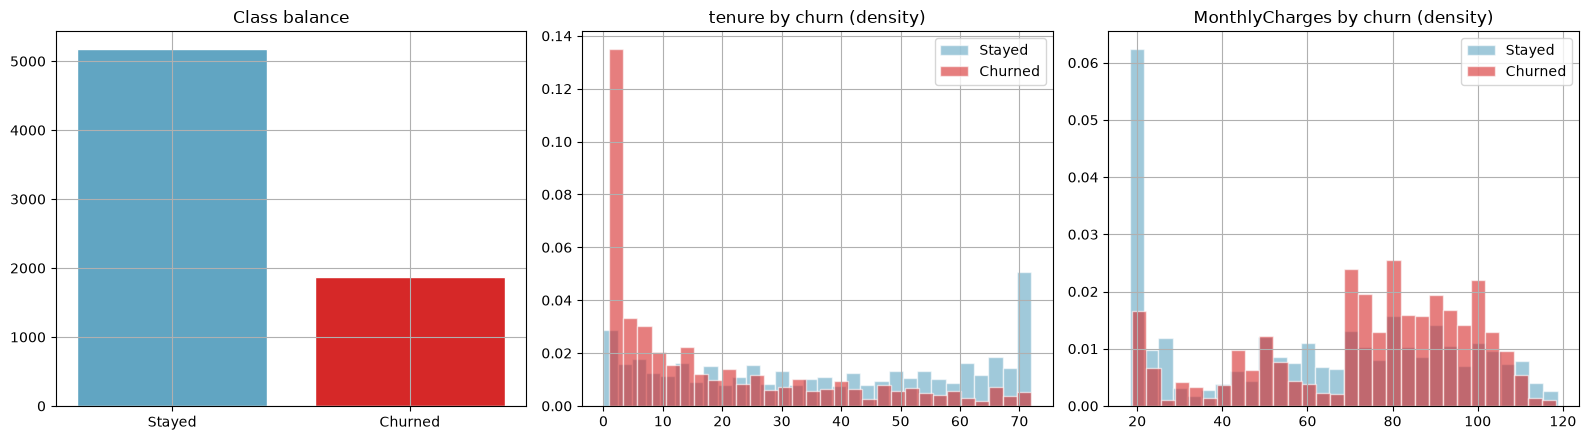

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
class_counts = telco_clean[TARGET_COLUMN].value_counts().sort_index()
axes[0].bar(["Stayed", "Churned"], class_counts.values, color=["#61a5c2", "#d62828"], edgecolor="white")
axes[0].set_title("Class balance")
for axis, column in zip(axes[1:], ["tenure", "MonthlyCharges"]):
    for churn_value, color, label in [(0, "#61a5c2", "Stayed"), (1, "#d62828", "Churned")]:
        axis.hist(telco_clean.loc[telco_clean[TARGET_COLUMN] == churn_value, column], bins=30, alpha=0.6, color=color, label=label, edgecolor="white", density=True)
    axis.set_title(f"{column} by churn (density)")
    axis.legend()
plt.tight_layout()
plt.show()

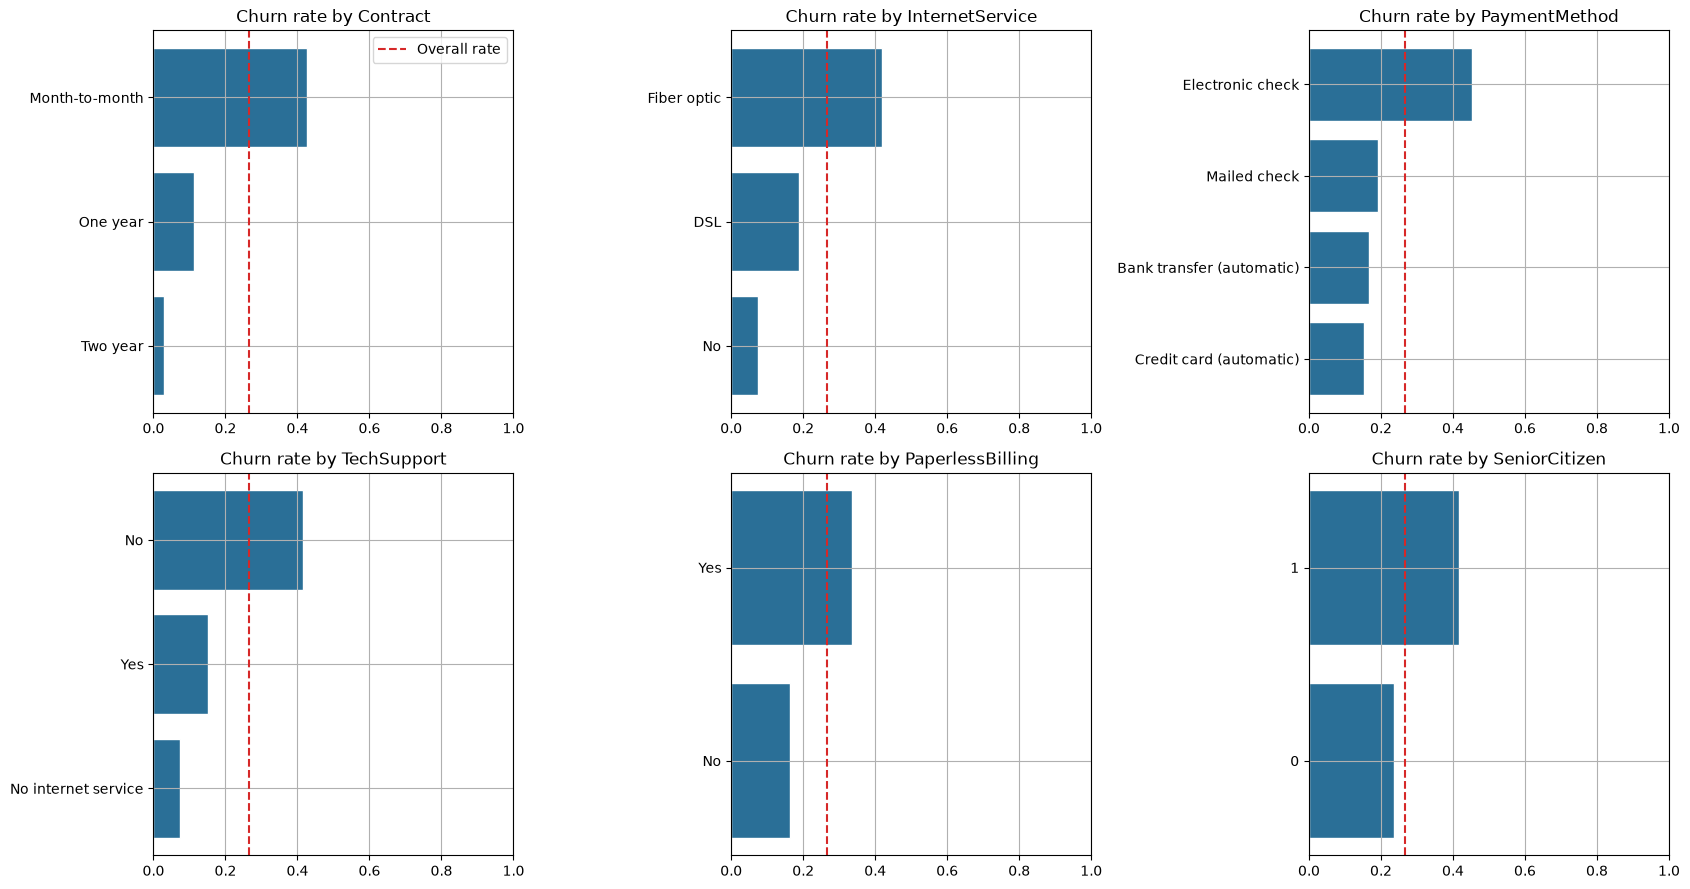

In [9]:
rate_columns = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling", "SeniorCitizen"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for axis, column in zip(axes.ravel(), rate_columns):
    churn_rate = telco_clean.groupby(column)[TARGET_COLUMN].mean().sort_values()
    axis.barh([str(label) for label in churn_rate.index], churn_rate.values, color="#2a6f97", edgecolor="white")
    axis.axvline(telco_clean[TARGET_COLUMN].mean(), color="#d62828", linestyle="--", label="Overall rate")
    axis.set_title(f"Churn rate by {column}")
    axis.set_xlim(0, 1)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

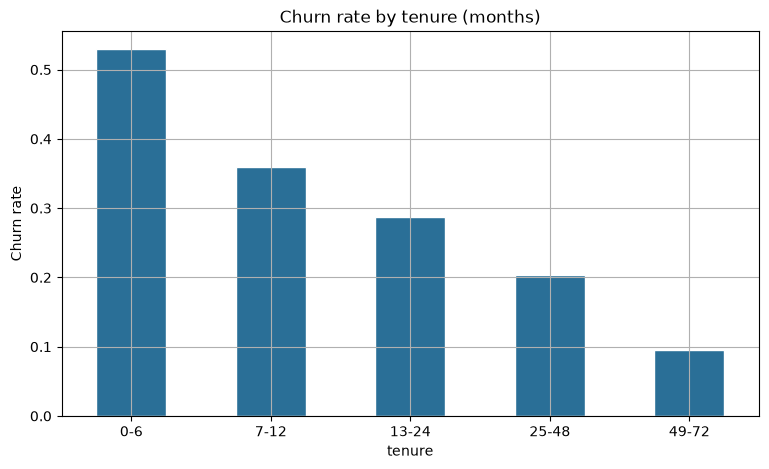

,mean,count
tenure,,
0-6,0.529,1481
7-12,0.359,705
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


In [10]:
tenure_bins = pd.cut(telco_clean["tenure"], bins=[-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
tenure_churn = telco_clean.groupby(tenure_bins, observed=True)[TARGET_COLUMN].agg(["mean", "count"])
ax = tenure_churn["mean"].plot(kind="bar", color="#2a6f97", edgecolor="white")
ax.set_title("Churn rate by tenure (months)")
ax.set_ylabel("Churn rate")
ax.tick_params(axis="x", rotation=0)
plt.show()
tenure_churn.round(3)

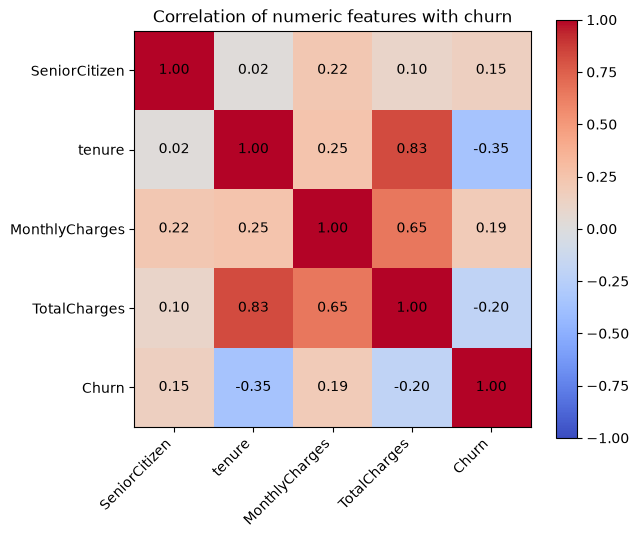

In [11]:
correlations = telco_clean[RAW_NUMERIC_COLUMNS + [TARGET_COLUMN]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations.columns)))
ax.set_yticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=45, ha="right")
ax.set_yticklabels(correlations.columns)
for row_index in range(len(correlations)):
    for column_index in range(len(correlations)):
        ax.text(column_index, row_index, f"{correlations.iloc[row_index, column_index]:.2f}", ha="center", va="center")
ax.grid(False)
fig.colorbar(image)
ax.set_title("Correlation of numeric features with churn")
plt.tight_layout()
plt.show()

## 7. Data Preprocessing

The split is stratified on the target and done **before** any statistic is learned. All imputation, scaling and one-hot encoding steps live inside a scikit-learn `Pipeline`, so they are fitted on the training data only (and on training folds during cross-validation).

In [12]:
feature_frame = telco_clean[RAW_FEATURE_COLUMNS]
target_series = telco_clean[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    feature_frame, target_series, test_size=0.2, stratify=target_series, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}  Test rows: {len(X_test):,}")
print(f"Churn rate  train: {y_train.mean():.3f}  test: {y_test.mean():.3f}")


def build_pipeline(estimator):
    numeric_transformer = Pipeline(
        [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    )
    categorical_transformer = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    preprocessor = ColumnTransformer(
        [
            ("numeric", numeric_transformer, NUMERIC_COLUMNS),
            ("categorical", categorical_transformer, CATEGORICAL_COLUMNS),
        ]
    )
    return Pipeline(
        [
            ("features", FunctionTransformer(add_features)),
            ("preprocess", preprocessor),
            ("model", estimator),
        ]
    )

Training rows: 5,634  Test rows: 1,409
Churn rate  train: 0.265  test: 0.265


## 8. Feature Engineering

`add_features` in `features.py` creates three features that describe the relationship of a customer with the company:

- `services_count`: how many of the optional services the customer uses (a measure of how deeply the customer is embedded)
- `is_new_customer`: tenure of twelve months or less
- `has_family`: the customer has a partner or dependents

In [13]:
engineered_preview = add_features(X_train)
engineered_rates = {
    column: pd.Series(y_train.values).groupby(engineered_preview[column].values).mean().round(3).to_dict()
    for column in ENGINEERED_COLUMNS
}
print("Churn rate by engineered feature value (training data):")
for column, rates in engineered_rates.items():
    print(f"  {column}: {rates}")
engineered_preview[ENGINEERED_COLUMNS].head()

Churn rate by engineered feature value (training data):
  services_count: {0: 0.429, 1: 0.212, 2: 0.438, 3: 0.35, 4: 0.277, 5: 0.226, 6: 0.127, 7: 0.052}
  is_new_customer: {0: 0.173, 1: 0.473}
  has_family: {0: 0.341, 1: 0.2}


,services_count,is_new_customer,has_family
3738,3,0,0
3151,2,0,1
4860,3,0,1
3867,5,0,1
3810,1,1,1


## 9. Model Training

Five algorithms are trained with the same preprocessing. Class weights are balanced where supported because the minority class (churn) is about a quarter of the customers.

In [14]:
candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE
    ),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=200, max_depth=4, class_weight="balanced", random_state=RANDOM_STATE
    ),
}

cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
}
cross_validation_rows = []
fitted_pipelines = {}

for model_name, estimator in candidate_models.items():
    pipeline = build_pipeline(estimator)
    scores = cross_validate(pipeline, X_train, y_train, cv=cross_validation, scoring=scoring)
    cross_validation_rows.append(
        {"model": model_name, **{f"cv_{metric}": scores[f"test_{metric}"].mean() for metric in scoring}, "cv_roc_auc_std": scores["test_roc_auc"].std()}
    )
    fitted_pipelines[model_name] = pipeline.fit(X_train, y_train)
    print(f"Trained {model_name}")

cross_validation_table = pd.DataFrame(cross_validation_rows).set_index("model")
cross_validation_table.round(4)

Trained Logistic Regression
Trained Decision Tree
Trained Random Forest
Trained Gradient Boosting
Trained Histogram Gradient Boosting


,cv_roc_auc,cv_average_precision,cv_f1,cv_recall,cv_precision,cv_roc_auc_std
model,,,,,,
Logistic Regression,0.8458,0.6618,0.6287,0.7980,0.5189,0.0120
Decision Tree,0.8247,0.6175,0.6127,0.7866,0.5023,0.0089
Random Forest,0.8452,0.6531,0.6320,0.7612,0.5405,0.0079
Gradient Boosting,0.8490,0.6695,0.5894,0.5311,0.6628,0.0118
Histogram Gradient Boosting,0.8473,0.6674,0.6333,0.7886,0.5291,0.0103


## 10. Model Comparison

All models are evaluated on the untouched test set with the default threshold of 0.5.

In [15]:
def classification_scores(model_name, fitted_pipeline, features_frame, target_values, threshold=0.5):
    probabilities = fitted_pipeline.predict_proba(features_frame)[:, 1]
    predicted_labels = (probabilities >= threshold).astype(int)
    return {
        "model": model_name,
        "accuracy": accuracy_score(target_values, predicted_labels),
        "precision": precision_score(target_values, predicted_labels),
        "recall": recall_score(target_values, predicted_labels),
        "f1": f1_score(target_values, predicted_labels),
        "roc_auc": roc_auc_score(target_values, probabilities),
        "average_precision": average_precision_score(target_values, probabilities),
    }


test_table = pd.DataFrame(
    [classification_scores(name, pipeline, X_test, y_test) for name, pipeline in fitted_pipelines.items()]
).set_index("model")
test_table.round(4)

,accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,
Logistic Regression,0.7346,0.5000,0.7914,0.6128,0.8412,0.6276
Decision Tree,0.7367,0.5025,0.7914,0.6147,0.8334,0.6225
Random Forest,0.7573,0.5295,0.7674,0.6266,0.8402,0.6456
Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8448,0.6623
Histogram Gradient Boosting,0.7544,0.5248,0.7914,0.6311,0.8423,0.6620


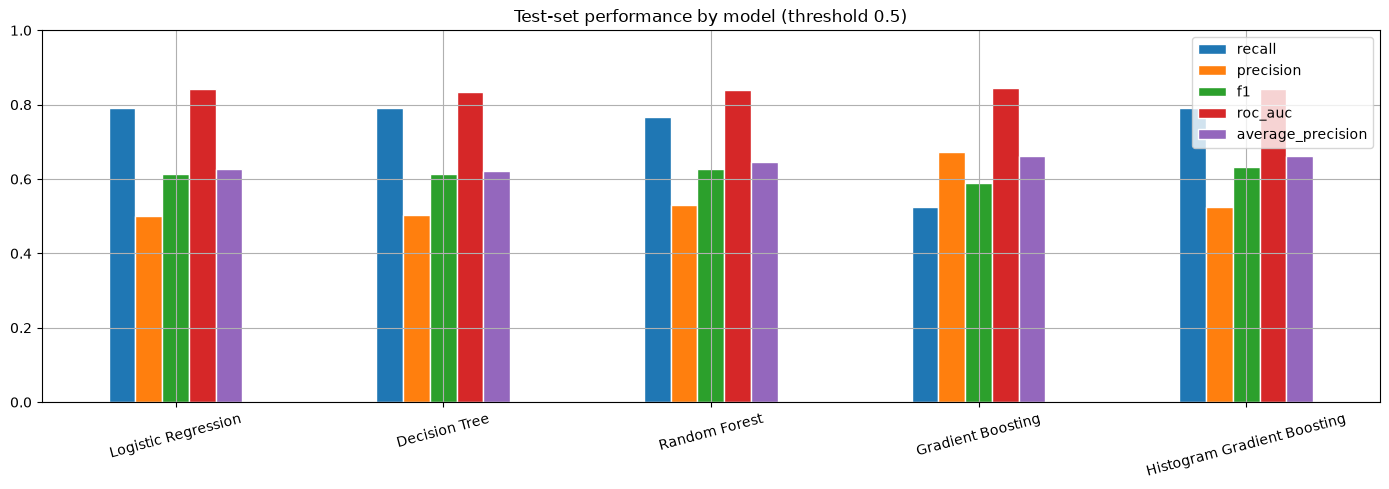

In [16]:
ax = test_table[["recall", "precision", "f1", "roc_auc", "average_precision"]].plot(kind="bar", figsize=(14, 5), edgecolor="white")
ax.set_title("Test-set performance by model (threshold 0.5)")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 11. Model Evaluation

The best model is chosen by cross-validated ROC AUC. Churn is imbalanced and a missed churner costs more than a false alarm, so the decision threshold is tuned for the best F1 score. It is selected from **out-of-fold predictions on the training set**, so the test set is not used for tuning.

In [17]:
best_model_name = cross_validation_table["cv_roc_auc"].idxmax()
best_pipeline = fitted_pipelines[best_model_name]

out_of_fold_probabilities = cross_val_predict(
    build_pipeline(candidate_models[best_model_name]), X_train, y_train, cv=cross_validation, method="predict_proba"
)[:, 1]
precision_values, recall_values, threshold_values = precision_recall_curve(y_train, out_of_fold_probabilities)
f1_values = 2 * precision_values[:-1] * recall_values[:-1] / (precision_values[:-1] + recall_values[:-1] + 1e-12)
decision_threshold = float(threshold_values[np.argmax(f1_values)])

print(f"Selected model: {best_model_name}")
print(f"Decision threshold chosen on training out-of-fold predictions: {decision_threshold:.3f}")

best_probabilities = best_pipeline.predict_proba(X_test)[:, 1]
best_predictions = (best_probabilities >= decision_threshold).astype(int)
print()
print(classification_report(y_test, best_predictions, target_names=["Stayed", "Churned"]))

Selected model: Gradient Boosting
Decision threshold chosen on training out-of-fold predictions: 0.322

              precision    recall  f1-score   support

      Stayed       0.89      0.78      0.83      1035
     Churned       0.54      0.73      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409



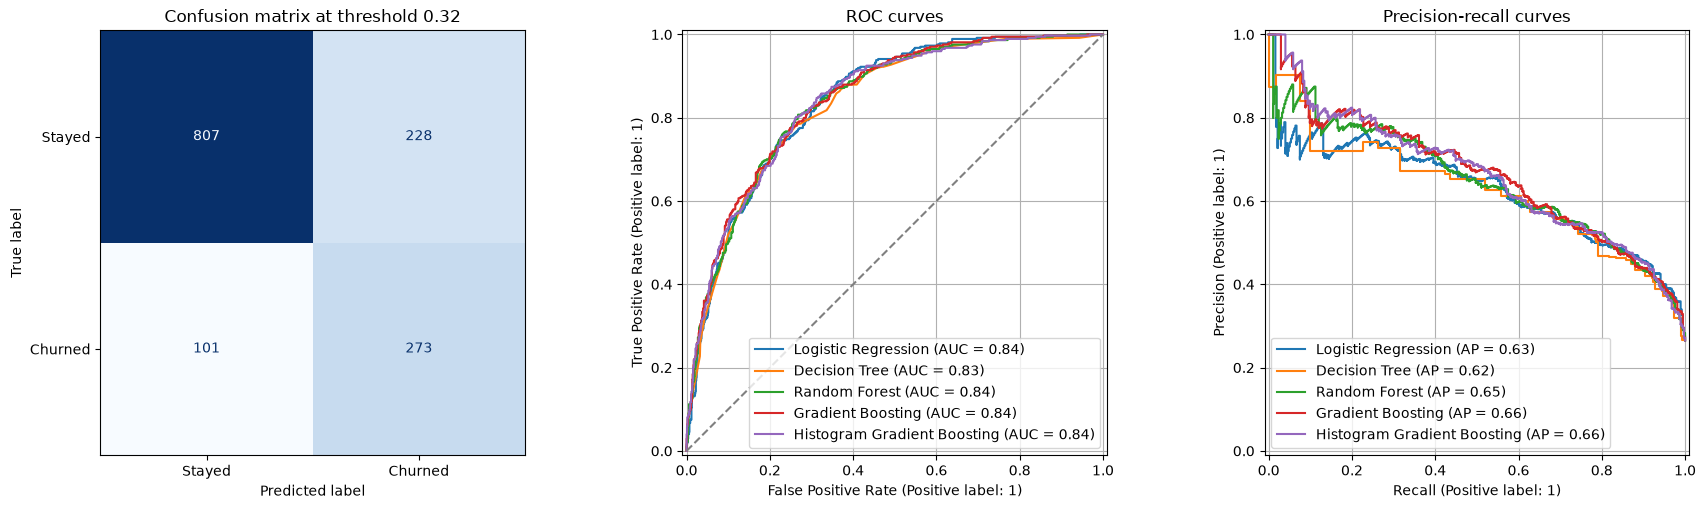

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, display_labels=["Stayed", "Churned"], cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title(f"Confusion matrix at threshold {decision_threshold:.2f}")
axes[0].grid(False)
for model_name, pipeline in fitted_pipelines.items():
    RocCurveDisplay.from_estimator(pipeline, X_test, y_test, ax=axes[1], name=model_name)
    PrecisionRecallDisplay.from_estimator(pipeline, X_test, y_test, ax=axes[2], name=model_name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set_title("ROC curves")
axes[2].set_title("Precision-recall curves")
plt.tight_layout()
plt.show()

### Key factors influencing churn

Two complementary views are used:

1. **Permutation importance** on the best model, measured on the original input columns.
2. **Logistic regression coefficients**, which show the direction of each effect: positive values increase the odds of churn and negative values decrease them.

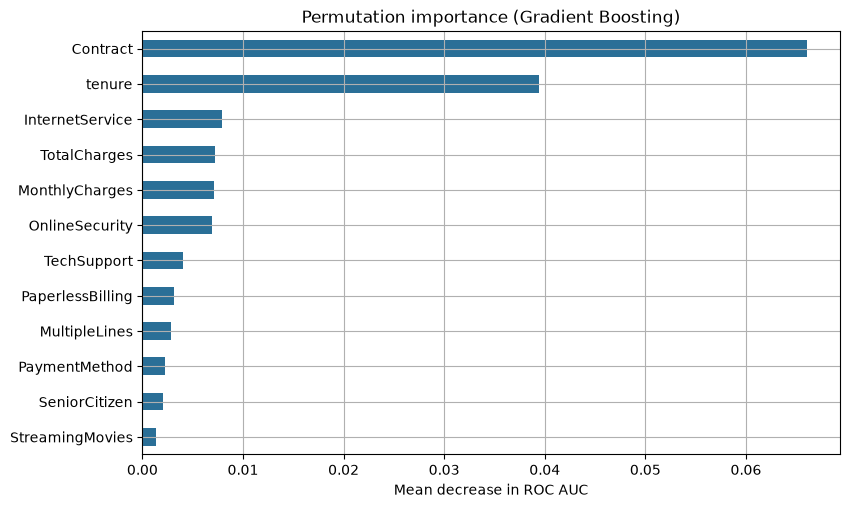

Contract            0.0660
tenure              0.0394
InternetService     0.0079
TotalCharges        0.0072
MonthlyCharges      0.0071
OnlineSecurity      0.0069
TechSupport         0.0041
PaperlessBilling    0.0031
MultipleLines       0.0029
PaymentMethod       0.0023
SeniorCitizen       0.0021
StreamingMovies     0.0013
dtype: float64

In [19]:
importance_result = permutation_importance(
    best_pipeline, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1
)
feature_importance = pd.Series(importance_result.importances_mean, index=X_test.columns).sort_values(ascending=False)
feature_importance.head(12).sort_values().plot(kind="barh", color="#2a6f97", figsize=(9, 5.5))
plt.title(f"Permutation importance ({best_model_name})")
plt.xlabel("Mean decrease in ROC AUC")
plt.show()
feature_importance.head(12).round(4)

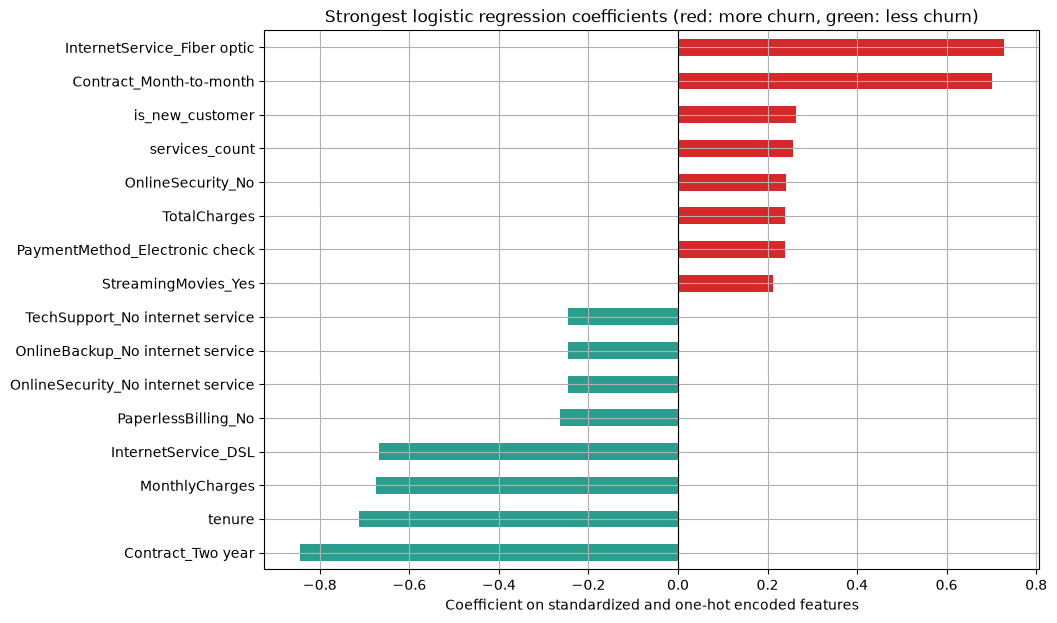

In [20]:
logistic_pipeline = fitted_pipelines["Logistic Regression"]
encoded_names = [
    name.split("__", 1)[1]
    for name in logistic_pipeline.named_steps["preprocess"].get_feature_names_out()
]
coefficients = pd.Series(logistic_pipeline.named_steps["model"].coef_[0], index=encoded_names).sort_values()
churn_drivers = pd.concat([coefficients.head(8), coefficients.tail(8)])
colors = ["#2a9d8f" if value < 0 else "#d62828" for value in churn_drivers.values]
churn_drivers.plot(kind="barh", color=colors, figsize=(10, 7))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Strongest logistic regression coefficients (red: more churn, green: less churn)")
plt.xlabel("Coefficient on standardized and one-hot encoded features")
plt.show()

## 12. Best Model Selection

The model with the highest mean cross-validated ROC AUC is selected, and its decision threshold comes from training data only. The test metrics below are therefore an honest estimate of how the model behaves on new customers.

In [21]:
best_test_metrics = classification_scores(best_model_name, best_pipeline, X_test, y_test, threshold=decision_threshold)
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]:
    print(f"Test {metric:<18}: {best_test_metrics[metric]:.4f}")

Test accuracy          : 0.7665
Test precision         : 0.5449
Test recall            : 0.7299
Test f1                : 0.6240
Test roc_auc           : 0.8448
Test average_precision : 0.6623


## 13. Model Saving

The complete pipeline is saved as `model.pkl`. The file `metadata.json` stores the input options, decision threshold, comparison table, drivers and ROC curve for the Streamlit app.

In [22]:
def json_default(value):
    return value.item() if hasattr(value, "item") else str(value)


numeric_ranges = {
    column: {
        "min": float(feature_frame[column].min()),
        "max": float(feature_frame[column].max()),
        "median": float(feature_frame[column].median()),
    }
    for column in RAW_NUMERIC_COLUMNS
}
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, best_probabilities)
curve_step = max(len(false_positive_rate) // 100, 1)

metadata = {
    "project": "Customer Churn Prediction",
    "target": TARGET_COLUMN,
    "best_model": best_model_name,
    "decision_threshold": decision_threshold,
    "overall_churn_rate": float(target_series.mean()),
    "numeric_ranges": numeric_ranges,
    "categories": {column: sorted(feature_frame[column].astype(str).unique().tolist()) for column in CATEGORICAL_COLUMNS},
    "test_metrics": best_test_metrics,
    "model_comparison": cross_validation_table.join(test_table, rsuffix="_test").reset_index().to_dict(orient="records"),
    "feature_importance": feature_importance.to_dict(),
    "churn_drivers": churn_drivers.to_dict(),
    "roc_curve": {
        "false_positive_rate": false_positive_rate[::curve_step].tolist(),
        "true_positive_rate": true_positive_rate[::curve_step].tolist(),
    },
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
}

joblib.dump(best_pipeline, "model.pkl")
with open("metadata.json", "w", encoding="utf-8") as metadata_file:
    json.dump(metadata, metadata_file, indent=2, default=json_default)
print("Saved model.pkl and metadata.json")

Saved model.pkl and metadata.json


## 14. Prediction on New Data

The saved model is loaded from disk and scores new customers described in the original column format.

In [23]:
loaded_model = joblib.load("model.pkl")

new_customers = pd.DataFrame(
    [
        {
            "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 2,
            "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic",
            "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No",
            "StreamingTV": "Yes", "StreamingMovies": "Yes", "Contract": "Month-to-month",
            "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check", "MonthlyCharges": 95.5, "TotalCharges": 191.0,
        },
        {
            "gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes", "tenure": 60,
            "PhoneService": "Yes", "MultipleLines": "Yes", "InternetService": "DSL",
            "OnlineSecurity": "Yes", "OnlineBackup": "Yes", "DeviceProtection": "Yes", "TechSupport": "Yes",
            "StreamingTV": "No", "StreamingMovies": "No", "Contract": "Two year",
            "PaperlessBilling": "No", "PaymentMethod": "Bank transfer (automatic)", "MonthlyCharges": 65.0, "TotalCharges": 3900.0,
        },
    ]
)[RAW_FEATURE_COLUMNS]

probabilities = loaded_model.predict_proba(new_customers)[:, 1]
new_customers["churn_probability"] = probabilities.round(3)
new_customers["prediction"] = np.where(probabilities >= decision_threshold, "Likely to churn", "Likely to stay")
consistency_check = np.allclose(loaded_model.predict_proba(X_test.head(50)), best_pipeline.predict_proba(X_test.head(50)))
print(f"Loaded model matches the in-memory model: {consistency_check}")
new_customers[["tenure", "Contract", "MonthlyCharges", "churn_probability", "prediction"]]

Loaded model matches the in-memory model: True


,tenure,Contract,MonthlyCharges,churn_probability,prediction
0,2,Month-to-month,95.5,0.779,Likely to churn
1,60,Two year,65.0,0.017,Likely to stay


## 15. Final Conclusion

In [24]:
top_features = ", ".join(feature_importance.head(4).index)
print(f"Best model by cross-validated ROC AUC: {best_model_name}")
print(f"Decision threshold: {decision_threshold:.3f}")
print(
    f"Test recall {best_test_metrics['recall']:.3f} | precision {best_test_metrics['precision']:.3f} | "
    f"F1 {best_test_metrics['f1']:.3f} | ROC AUC {best_test_metrics['roc_auc']:.3f} | average precision {best_test_metrics['average_precision']:.3f}"
)
print(f"Most important features: {top_features}")
print(f"Strongest churn-increasing signal in the logistic model: {coefficients.idxmax()}")
print(f"Strongest churn-decreasing signal in the logistic model: {coefficients.idxmin()}")
print()
print("Model ranking on the test set (ROC AUC):")
print(test_table["roc_auc"].sort_values(ascending=False).round(4).to_string())

Best model by cross-validated ROC AUC: Gradient Boosting
Decision threshold: 0.322
Test recall 0.730 | precision 0.545 | F1 0.624 | ROC AUC 0.845 | average precision 0.662
Most important features: Contract, tenure, InternetService, TotalCharges
Strongest churn-increasing signal in the logistic model: InternetService_Fiber optic
Strongest churn-decreasing signal in the logistic model: Contract_Two year

Model ranking on the test set (ROC AUC):
model
Gradient Boosting              0.8448
Histogram Gradient Boosting    0.8423
Logistic Regression            0.8412
Random Forest                  0.8402
Decision Tree                  0.8334


**Summary of the approach**

- The analysis shows which customer groups churn most, and the model turns these patterns into a probability for each customer.
- Class weighting, ROC AUC and average precision keep the evaluation meaningful on imbalanced data, and the decision threshold was tuned on training data only.
- The saved file contains the complete pipeline, so the Streamlit app scores customers exactly as the notebook does.

**Limitations and next steps**

- Churn is influenced by factors that are not in this dataset, such as competitor offers and service quality.
- The dataset is a single snapshot, so the model cannot learn how behaviour changes over time.
- Possible improvements: hyperparameter search, cost-sensitive threshold selection with real retention costs, SHAP explanations for individual customers and monitoring for drift.